In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
from Minimal_Model_2D import *
from charge_trap_pot_model import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
'''
class Image_charge_calculator:

    ### Following ELECTRIC FIELDS IN DIELECTRIC MULTI-LAYERS CALCULATED BY DIGITAL COMPUTER by Takeshi Takashima an, Ryozo Ishibashi
    ### IEEE Trans. Electr. Insul, Vol EI-13, No 1, February 1978 

    ###################################################################################################################################################

    def __init__(self, q_ct, z_ct, ep_ge, ep_sige, ep_ox, t_sige, t_ox, r):
        
        self.q_ct = q_ct  # Initial charge q_1i
        self.z_ct = z_ct # position of initial charge q 
        self.ep1 = ep_ge  # dielectric constant 1 (rightmost layer)
        self.ep2 = ep_sige  # dielectric constant 2 (middle layer)
        self.ep3 = ep_ox  # dielectric constant 3 (leftmost layer, has conductor to the left of it) 
        #self.a = a  # thickness dielectric 1
        self.b = t_sige  # thickness dielectric 2
        self.c = t_ox  # thickness dielectric 3
        self.delta = r  # Small positive number for termination condition
        self.image_charges_q5s = []  # Store generated image charges
        self.image_charges_q4s = []  # Store generated image charges
        self.image_charges_q3s = []  # Store generated image charges
        self.image_charges_q2s = []  # Store generated image charges
        self.image_charges_q1s = []  # Store generated image charges

        self.alpha12 = ( self.ep1 - self.ep2 )/ (self.ep1 + self.ep2)
        self.beta12 = 1- self.alpha12

        self.alpha21 = -self.alpha12
        self.beta21 = 1 - self.alpha21

        self.alpha23 = ( self.ep2 - self.ep3 )/ (self.ep2 + self.ep3)
        self.beta23 = 1 - self.alpha23

        self.alpha32 = - self.alpha23 
        self.beta32 = 1 - self.alpha32

        #self.q0 = self.alpha12* self.q_initial
        #self.q11 = self.beta12 * self.q_initial

    def rule_i(self, q1i, z1i, level):

        if abs(q1i / self.q_ct) < self.delta:
            return  # Termination condition

        q2j = self.alpha23 * q1i
        z2j =  - z1i + 2* self.c
        q3k = self.beta23 * q1i
        z3k =  z1i
        
        self.image_charges_q2s.append((q2j, z2j, level, 'q2j'))
        self.image_charges_q3s.append((q3k, z3k, level, 'q3k'))
        
        self.rule_ii(q2j, z2j, level + 1)
        self.rule_iii(q3k, z3k, level + 1)

    def rule_ii(self, q2i, z2i, level):

        if abs(q2i / self.q_ct) < self.delta:
            return  # Termination condition
        
        q1j = self.alpha21 * q2i
        z1j = 2*(self.b + self.c) - z2i
        q5k = self.beta21 * q2i
        z5k = z2i
        
        self.image_charges_q1s.append((q1j, z1j, level, 'q1j'))
        self.image_charges_q5s.append((q5k, z5k, level, 'q5k'))

        #print("image charge = ", q5k , "co-ordinate = ", x5k, "level =", level, "\n")
        
        self.rule_i(q1j, z1j, level + 1)

    def rule_iii(self, q3i, z3i, level):

        if abs(q3i / self.q_ct) < self.delta:
            return  # Termination condition

        q4j = -1 * q3i
        z4j = -z3i
        
        self.image_charges_q4s.append((q4j, z4j, level, 'q4j'))
        self.rule_iv(q4j, z4j, level + 1)

    def rule_iv(self, q4i, z4i, level):

        if abs(q4i / self.q_ct) < self.delta:
            return  # Termination condition

        q3j = self.alpha32 * q4i
        z3j = -z4i + 2*self.c
        q2k = self.beta32 * q4i
        z2k = z4i
        
        self.image_charges_q3s.append((q3j, z3j, level, 'q3j'))
        self.image_charges_q2s.append((q2k, z2k, level, 'q2k'))
        
        self.rule_iii(q3j, z3j, level + 1)
        self.rule_ii(q2k, z2k, level + 1)


    def calc_image_charges(self):

        q40 = self.q_ct
        z40 = self.z_ct
        level = 0

        q41 = -self.q_ct
        z41 = -self.z_ct
        level = 0

        self.image_charges_q4s.append((q40, z40, level, 'q4j'))
        self.image_charges_q4s.append((q41, z41, level, 'q4j'))
        self.rule_iv(q40, z40, level + 1)
        self.rule_iv(q41, z41, level + 1)

        return self.image_charges_q5s, self.image_charges_q4s, self.image_charges_q3s, self.image_charges_q2s, self.image_charges_q1s

        '''

'\nclass Image_charge_calculator:\n\n    ### Following ELECTRIC FIELDS IN DIELECTRIC MULTI-LAYERS CALCULATED BY DIGITAL COMPUTER by Takeshi Takashima an, Ryozo Ishibashi\n    ### IEEE Trans. Electr. Insul, Vol EI-13, No 1, February 1978 \n\n    ###################################################################################################################################################\n\n    def __init__(self, q_ct, z_ct, ep_ge, ep_sige, ep_ox, t_sige, t_ox, r):\n        \n        self.q_ct = q_ct  # Initial charge q_1i\n        self.z_ct = z_ct # position of initial charge q \n        self.ep1 = ep_ge  # dielectric constant 1 (rightmost layer)\n        self.ep2 = ep_sige  # dielectric constant 2 (middle layer)\n        self.ep3 = ep_ox  # dielectric constant 3 (leftmost layer, has conductor to the left of it) \n        #self.a = a  # thickness dielectric 1\n        self.b = t_sige  # thickness dielectric 2\n        self.c = t_ox  # thickness dielectric 3\n        self.delta = r  

In [3]:
'''
class Image_charge_model(twoD_Minimal_Model):

    def __init__(self, n, nsm, nsc, m, ax, ay, omega=0, alphat=0, delta=0, meff_sc=1, meff_sm = 1 , mu_sc = 0, mu_sm=0, dis_mean=0, dis_var=1, px=False, py=False,  epsilon=0, ep_ge=16.2, ep_sige=12.75, ep_ox=8, t_sige=40, t_ox=8, r=1e-5 ):  # Additional arguments  in Child

        super().__init__(n, nsm, nsc, m, ax, ay, omega, alphat, delta, meff_sc, meff_sm, mu_sc, mu_sm, dis_mean, dis_var, px, py,  epsilon)  
        
        self.ep_ge = ep_ge  # dielectric constant 1 (rightmost layer)
        self.ep_sige = ep_sige  # dielectric constant 2 (middle layer)
        self.ep_ox = ep_ox  # dielectric constant 3 (leftmost layer, has conductor to the left of it) 
        #self.a = a  # thickness dielectric 1
        self.t_sige = t_sige  # thickness dielectric 2
        self.t_ox = t_ox  # thickness dielectric 3
        self.r = r  # Small positive number for termination condition

    def charge_trap_pot(self, x_ct= 0, y_ct=0, z_ct=2, z_im=0, x=0, y=0, z=0):

        ### here z_im is redundant #####

        ###q_ct = 1 because charge value is included in cont k0_e #### 

        self.image_charges_q5s, self.image_charges_q4s, self.image_charges_q3s, self.image_charges_q2s, self.image_charges_q1s = Image_charge_calculator(q_ct=1, z_ct=z_ct, ep_ge=self.ep_ge, ep_sige=self.ep_sige, ep_ox=self.ep_ox, t_sige=self.t_sige, t_ox=self.t_ox, r=self.r).calc_image_charges()

        #print(self.image_charges_q5s)

        pot = 0

        for image_chrg in self.image_charges_q5s:

            pot = pot+ image_chrg[0]/ math.sqrt((z-image_chrg[1])**2+(y-y_ct)**2+(x-x_ct)**2)


        return k0_e/self.ep_ge*pot ### k0_e is 1/4/pi/epsilon0*ee in meV-nm 

'''

'\nclass Image_charge_model(twoD_Minimal_Model):\n\n    def __init__(self, n, nsm, nsc, m, ax, ay, omega=0, alphat=0, delta=0, meff_sc=1, meff_sm = 1 , mu_sc = 0, mu_sm=0, dis_mean=0, dis_var=1, px=False, py=False,  epsilon=0, ep_ge=16.2, ep_sige=12.75, ep_ox=8, t_sige=40, t_ox=8, r=1e-5 ):  # Additional arguments  in Child\n\n        super().__init__(n, nsm, nsc, m, ax, ay, omega, alphat, delta, meff_sc, meff_sm, mu_sc, mu_sm, dis_mean, dis_var, px, py,  epsilon)  \n        \n        self.ep_ge = ep_ge  # dielectric constant 1 (rightmost layer)\n        self.ep_sige = ep_sige  # dielectric constant 2 (middle layer)\n        self.ep_ox = ep_ox  # dielectric constant 3 (leftmost layer, has conductor to the left of it) \n        #self.a = a  # thickness dielectric 1\n        self.t_sige = t_sige  # thickness dielectric 2\n        self.t_ox = t_ox  # thickness dielectric 3\n        self.r = r  # Small positive number for termination condition\n\n    def charge_trap_pot(self, x_ct= 0, y_ct

In [4]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)




ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

V = ModCT.charge_trap_pot(0,0,4,0, 0,0,50)

print(V)

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418
0.4607777883669817


In [5]:
ModCT = twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM) 

V = ModCT.charge_trap_pot(z_ct=50, z_im=52)

print(V)

0.10701843764752383


In [6]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)


lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [7]:

ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, ep_ge=11.7, ep_sige=12.7, t_ox=5, t_sige=41)

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
ZCT = 1
ZIM = 0 #immaterial
ZQW = 51


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

2.5183683665938907e-07


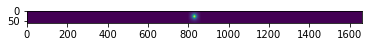

In [8]:
K = V_lat.diagonal()
J = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


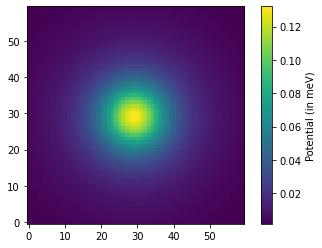

In [9]:
fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')


In [10]:
ModCT = twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM) 

V = ModCT.charge_trap_pot(z_ct=50, z_im=52)

print(V)

0.10701843764752383


2.817938033976227e-07


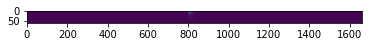

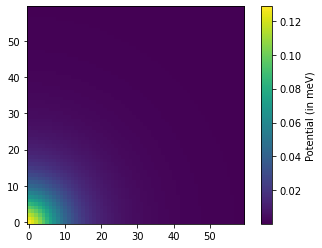

In [11]:
ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, ep_ge=11.7, ep_sige=12.7, t_ox=5, t_sige=41)

#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY
XCT = NSC*AX
YCT = 0
ZCT = 1
ZIM = 0 #immaterial
ZQW = 51


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')


2.2167474852668606e-07


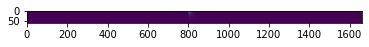

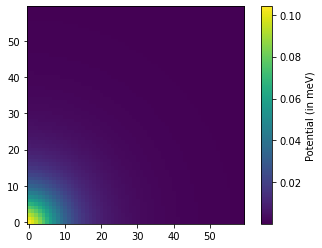

In [12]:
ModCT = twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY
XCT = NSC*AX
YCT = 0
ZCT = 50                  ### equivalent coordinate to image charge model 
ZIM = 52                  ### equivalent coordinate to image charge model 
ZQW = 0                   ### equivalent coordinate to image charge model 


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')


2.817938033976227e-07


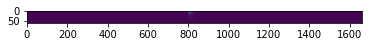

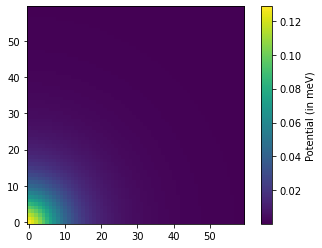

In [13]:
ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, ep_ge=11.7, ep_sige=12.7, t_ox=5, t_sige=41)

#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY
XCT = NSC*AX
YCT = 0
ZCT = 1
ZIM = 0 #immaterial for image charge model
ZQW = 51


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J_si_img_chrg_model = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J_si_img_chrg_model)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_si_img_chrg_model[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')


3.784419258951735e-07


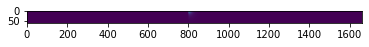

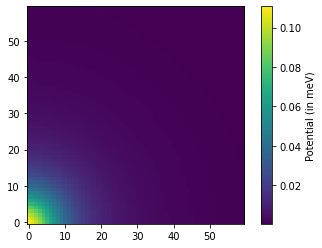

In [14]:
ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, ep_ge=16.2, ep_sige=12.7, t_ox=5, t_sige=41)

#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY
XCT = NSC*AX
YCT = 0
ZCT = 1
ZIM = 0 #immaterial for image charge model
ZQW = 51


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J_ge_img_chrg_model = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J_ge_img_chrg_model)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_ge_img_chrg_model[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')

2.2167474852668606e-07


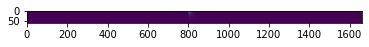

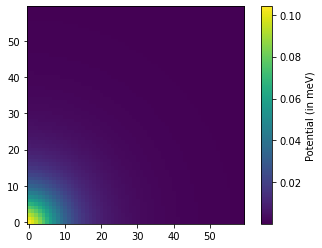

In [15]:
ModCT = twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY
XCT = NSC*AX
YCT = 0
ZCT = 50                  ### equivalent coordinate to image charge model 
ZIM = 52                  ### equivalent coordinate to image charge model 
ZQW = 0                   ### equivalent coordinate to image charge model 


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J_si_two_d_model = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J_si_two_d_model)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_si_two_d_model[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')

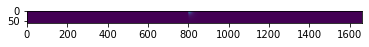

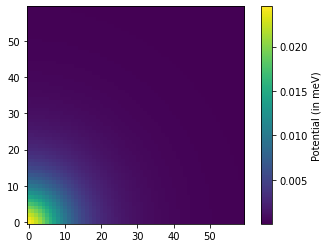

In [16]:

J_diff = J_si_img_chrg_model - J_si_two_d_model

plt.figure(figsize=(6, 6))
plt.imshow(J_diff)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_diff[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')


1.9872049958776483e-06


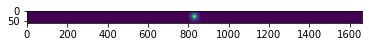

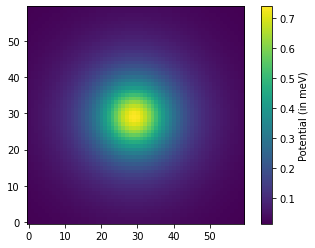

In [29]:
ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, ep_ge=11.7, ep_sige=12.7, t_ox=7, t_sige=48)

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
#XCT = NSC*AX
#YCT = 0
ZCT = 7
ZIM = 0 #immaterial for image charge model
ZQW = 57


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J_si_img_chrg_model = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J_si_img_chrg_model)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_si_img_chrg_model[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')


2.7166399188287295e-06


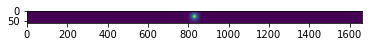

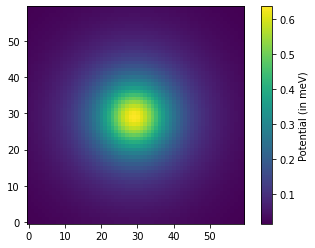

In [28]:
ModCT = Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, ep_ge=16.2, ep_sige=12.7, t_ox=7, t_sige=48)

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
#XCT = NSC*AX
#YCT = 0
ZCT = 7
ZIM = 0 #immaterial for image charge model
ZQW = 57


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J_ge_img_chrg_model = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J_ge_img_chrg_model)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_ge_img_chrg_model[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')

1.5498350570131298e-06


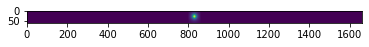

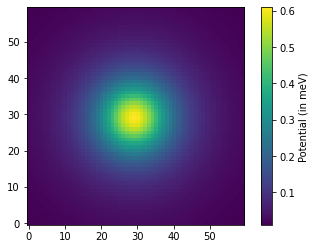

In [30]:
ModCT = twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
#XCT = NSC*AX
#YCT = 0
ZCT = 50                  ### equivalent coordinate to image charge model 
ZIM = 64                  ### equivalent coordinate to image charge model 
ZQW = 0                   ### equivalent coordinate to image charge model 


V = ModCT.charge_trap_pot(XCT,YCT,ZCT,ZIM, 0,0,ZQW)

V_lat = ModCT.charge_pot_lattice(XCT,YCT,ZCT,ZIM,ZQW)

print(V)

K = V_lat.diagonal()
J_si_two_d_model = K.reshape(M,NTOT)


plt.figure(figsize=(6, 6))
plt.imshow(J_si_two_d_model)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_si_two_d_model[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')

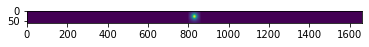

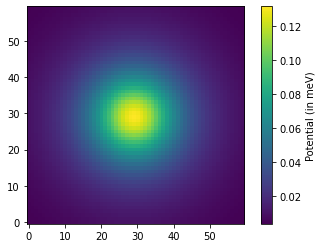

In [31]:

J_diff = J_si_img_chrg_model - J_si_two_d_model

plt.figure(figsize=(6, 6))
plt.imshow(J_diff)
plt.axis("image")  # Ensures square display by adjusting axis limits
plt.show()


fig = plt.figure()
ax = fig.add_subplot(111)

cax = ax.imshow(J_diff[:, NSC:NSC+NSM], aspect='auto', origin='lower')

cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('charge_trap_pot.png', bbox_inches='tight')
